## STEP 0: Generation of Matrix

In [51]:
import numpy as np

# Visualization setings
np.set_printoptions(precision=6, suppress=True)

def gerar_matrizes(matricula) :
    """
    Gera as matrizes dos Problemas 1 e 2 a partir de uma matrícula com 6 digitos .
    """
    digitos = [int(d) for d in str(matricula)]

    if len(digitos) != 6:
        raise ValueError("A matrícula deve possuir exatamente 6 digitos.")

    d1, d2, d3, d4, d5, d6 = digitos

    # Problema 1
    A1 = np.array([
    [17 + d1, d2, 34 + d3, 24 + d4],
    [7 + d5, 15 + d6, 3 + d1, 9 + d2],
    [2, 0, d3, 31],
    [0, 0, 0, 31 + d4]
    ], dtype=float)

    # Problema 2
    A2 = np . array ([
    [-5 - d1, -1, 0, 2, 1],
    [-7, -1 - d2, 9, 7, 2],
    [4, 3, 8 + d3, -2, -2],
    [-7, 3, 4, -6 - d4, -2],
    [0, -2, -7, -7, -9 - d5]
    ], dtype=float)

    return A1, A2

matricula = 318375
A1, A2 = gerar_matrizes(matricula)

print("\nMatriz do Problema 1: ")
print(A1)
print("\nMatriz do Problema 2: ")
print(A2)


Matriz do Problema 1: 
[[20.  1. 42. 27.]
 [14. 20.  6. 10.]
 [ 2.  0.  8. 31.]
 [ 0.  0.  0. 34.]]

Matriz do Problema 2: 
[[ -8.  -1.   0.   2.   1.]
 [ -7.  -2.   9.   7.   2.]
 [  4.   3.  16.  -2.  -2.]
 [ -7.   3.   4.  -9.  -2.]
 [  0.  -2.  -7.  -7. -16.]]


Na matriz $A_1$, o elemento $a_{31} = 2 \neq 0$, assim a matriz não está na forma de Hessenberg superior (elementos abaixo da subdiagonal iguais a zero), com isso, temos um impedimento de uso direto do algoritmo QR sobre esta matriz porque:

1. A fatoração QR via Householder ou Gram-Schmidt modificado custa $O(n^3)$ operações de ponto flutuante. Como a convergência global para a matriz de Schur exige $O(n)$ iterações, o esforço computacional total escalaria para $O(n^4)$.
    
    1.1 Se $A$ for previamente reduzida a uma matriz de Hessenberg superior $H$, a estrutura esparsa abaixo da subdiagonal permite que a fatoração $H=QR$ aniquile apenas um único elemento por coluna, substituindo o uso pesado de Householder por uma sequência de $n - 1$ rotações de Givens planas, levando o custo computacional de $O(n^3)$ para $O(n^2)$. Assim, o custo global de convergência cai para $O(n^3)$.

2. A matriz de Hessenberg é invariante sob a iteração QR: se $H_{k} = Q_{k}R_{k}$ é a fatoração de uma matriz de Hessenberg superior, a próxima matriz na sequência de similaridade, $H_{k+1} = Q_{k+1}R_{k+1}$, também é garantidamente de Hesseberg superior. O algoritmo QR revela os autovalores conduzindo os elementos subdiagonais a zero. Quando um elemento subdiagonal atinge uma magnitude tolerável próxima ao épsilon da aritmética de máquina,  $\epsilon_{mach}$, a matriz experimenta o fenômeno de "deflação" ou "desacoplamento espectral", particionando-se em blocos: $H = \begin{bmatrix} H_{11} & H_{12} \\ 0 & H_{22} \end{bmatrix}$. Isso quebra o problema original de dimensão $n$ em subproblemas independentes e menores, permitindo que as iterações subsequentes foquem apenas no bloco ativo.

Além disso, na linha 4 de $A_1$ o elemento $a_{43} = 0$ já está desacoplado, o que implica que $\lambda = 34$ já é um autovalor visível por inspeção, e o algoritmo de Hessenberg + QR preservará essa estrutura.

## STEP 1: The Hessenberg Reduction

No problema 1a nosso objetivo é obter a Decomposição Real de Schur: $A = QTQ^T \iff Q^TAQ = T$, onde $Q \in \mathbb{R}^{n \times n}$ é ortogonal ($Q^TQ = I$) e $T \in \mathbb{R}^{n \times n}$ é quase triangular superior (triangular superior em blocos $1 \times 1$ para autovalores reais e blocos $2 \times 2$ para pares de autovalores complexos conjugados).
Assim, precisamos primeiramente contruir uma matriz ortogonal $U = P_1P_2 \dots P_{n-2}$ (produto de reflexões de Householder), tal que:

$$H = U^TAU$$

seja Hessenberg superior. Com isso, aplicando as rotações de Givens sobre $H$ e acumulando-as na própria matriz ortogonal, obteremos a matriz $Q$ final da decomposição de Schur.

### 1.1. Reflexão de Householder

Dado um vetor coluna $x \in \mathbb{R}^m$, queremos encontrar um vetor $v \in \mathbb{R}^m$ e uma constante $c = \frac{2}{v^Tv}$ tais que a matriz de reflexão de Householder:

$$P = I - cvv^T$$

reflita $x$ sobre o primeiro eixo canônico $e_1 = [1, 0, \dots, 0]^T$, zerando todas as componentes de $x$ abaixo da primeira:

$$Px = (I - cvv^T)x = \alpha e_1, \text{onde } \alpha = \pm \|x\|_2$$

Para construir $v$ de forma numericamente estável, evitando cancelamento catastrófico na subtração de números de mesmo sinal:

1. Calculamos a norma euclidiana $\|x\|_2 = \sqrt{\sum_{i=1}^m x_i^2}$ com a função `calc_norm_2()`:

In [52]:
# Calculation of norm-2
def calc_norm_2(x: np.ndarray) -> float:
    """Calculates the euclidian norm-2 of a vector: sqrt(x^T x)."""
    return float(np.sqrt(np.sum(x ** 2)))

2. Escolhemos o sinal de $\alpha$ oposto ao sinal da primeira componente $x_1$:
$$\alpha = -\operatorname{sign}(x_1)\|x\|_2 \quad (\text{usando }\operatorname{sign}(x_1) = 1 \text{ se } x_1 \ge 0 \text{ e } -1 \text{ se } x_1 < 0)$$

3. Definimos o vetor de Householder:
$$v = x - \alpha e_1 \implies \begin{cases} v_1 = x_1 - \alpha = x_1 + \operatorname{sign}(x_1)\|x\|_2 \\ v_i = x_i, \quad \text{para } i = 2, \dots, m \end{cases}$$

4. Calculamos $c = \frac{2}{v^Tv}$ (com a proteção de que, se $vTv = 0$, então $c = 0$).

A função `house()` implementa os passos 2, 3 e 4 descritos anteriormente:

In [53]:
# Calculation of Householder Reflexition
def house(x: np.ndarray):
    """
    Calculates the vextor v of Householder and the scalar c = 2 / (v^T v)
    such that P*x = (I - c * v * v^T)*x = alpha * e_1
    """
    # Ensuring that x is treated as a 1D vector to facilitate manipulation
    x_vec = x.flatten().astype(float).copy()
    x_norm = calc_norm_2(x_vec)

    # If all the entries below x[0] are already zero, we don't need to reflect.
    if calc_norm_2(x_vec[1:]) == 0:
        v = np.zeros_like(x_vec).reshape(-1, 1)     # Copy vector x with entries equal to 0, and transform v into a column vector (m x 1)
        c = 0.0
        return v, c
    
    # Item 2: Choose the opposite alpha sign to x[0] to avoid catastrophic cancellation.
    sign = 1.0 if x_vec[0] >= 0.0 else -1.0
    alpha = -sign * x_norm

    # Item 3: v = x - alpha * e_1
    v = x_vec.copy()
    v[0] = v[0] - alpha
    v = v.reshape(-1, 1)        # Transform v into a column vector (m x 1)

    # Item 4: c = 2 / (v^T v)
    vTv = float((v.T @ v)[0, 0])        # [0, 0] extracts the pure scalar
    c = 2.0 / vTv if vTv > 0.0 else 0.0

    return v, c

### 1.2 Hessenberg Reduction
A função `hessenberg_reduction()` implementa o algoritmo de redução de Hessenberg, recebendo uma matriz $A \in \mathbb{R}^{n \times n}$ e tendo como saída a matriz ortogonal $U$ e a matriz de Hessinberg superior $H$, tais que $H = U^TAU$. Nesta função, no passo $j$ começamos na linha $j + 1$ into até $n$: $x = H(j + 1:n, j)$. Assim:

* Multiplicar à esquerda por $P_j^T$ combina apenas as linhas $j + 1$ até $n$, zerando as entradas $j + 2$ até $n$ da coluna $j$ abaixo da subdiagonal.
* Multiplicar à direita por $P_j$ combina apenas as colunas $j + 1$ até $n$, não alterando a coluna $j$ e preservando os zeros recém-criados.

Se usássemos uma reflexão $P_1$ para zerar as entradas 2 até $n$ da primeira coluna, como fazemos na fatoração QR tradicional, ao multiplicarmos à direita na transformação de similaridade $P_1^TAP_1$, a multiplicação por $P_1$ combinaria a primeira coluna com as demais e destruiria todos os zeros já criados.

In [54]:
def hessenberg_reduction(A: np.ndarray):
    """Hessenberg Reduction algorithm."""
    n = A.shape[0]
    U = np.eye(n, dtype=float)
    H = A.astype(float).copy()

    for j in range(n - 2):
        # v = house(H(j+1:n, j)), c = 2 / (v^T v)
        x_sub = H[j + 1 : n, j]
        v, c = house(x_sub)

        if c != 0.0:
            # H(j+1:n, j:n) = H(j+1:n, j:n) - c * v * (v^T * H(j+1:n, j:n))
            H[j + 1 : n, j:n] = H[j + 1 : n, j:n] - c * (
                v @ (v.T @ H[j + 1 : n, j:n])
            )

            # H(1:n, j+1:n) = H(1:n, j+1:n) - c * (H(1:n, j+1:n) * v) * v^T
            H[:, j + 1 : n] = H[:, j + 1 : n] - c * ((H[:, j + 1 : n] @ v) @ v.T)

            # U(1:n, j+1:n) = U(1:n, j+1:n) - c * (U(1:n, j+1:n) * v) * v^T
            U[:, j + 1 : n] = U[:, j + 1 : n] - c * ((U[:, j + 1 : n] @ v) @ v.T)

    return U, H

In [55]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# ==============================================================================
# DEFINIÇÃO DA PALETA FÍSICA DE ENERGIA
# -infinito -> Preto / Vermelho escuro (mínimo de energia)
# 0.00      -> Branco puro (estado neutro / zero de energia)
# +infinito -> Violeta profundo (máximo de energia)
# ==============================================================================
nos_cores = [
    (0.00, "#1a0002"),  # Preto / Vermelho profundíssimo (-infinito)
    (0.12, "#800000"),  # Vermelho escuro (-15.00)
    (0.30, "#d32f2f"),  # Vermelho vivo
    (0.44, "#ef9a9a"),  # Rosa salmão claro visível
    (0.50, "#ffffff"),  # BRANCO PURO EXCLUSIVO PARA O ZERO (0.00)
    (0.53, "#64b5f6"),  # Azul celeste nítido (+1.0 a +2.0)
    (0.70, "#1976d2"),  # Azul clássico
    (0.88, "#4a148c"),  # Violeta (+42.00)
    (1.00, "#1a0033"),  # Violeta escuro (+infinito)
]
cmap_fisica = LinearSegmentedColormap.from_list(
    "escala_fisica", nos_cores, N=513
)


def renderizar_matriz(
    ax, matriz, titulo, vmin=None, vmax=None, threshold_zero=1e-10
):
  """Renderiza uma matriz como mapa de calor com escala física de energia."""
  matriz_plot = matriz.copy()
  matriz_plot[np.abs(matriz_plot) < threshold_zero] = 0.0

  if vmin is None or vmax is None:
    max_val = np.max(np.abs(matriz))
    norm = TwoSlopeNorm(
        vmin=-max_val if max_val > 0 else -1.0,
        vcenter=0.0,
        vmax=max_val if max_val > 0 else 1.0,
    )
  else:
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

  cax = ax.matshow(matriz_plot, cmap=cmap_fisica, norm=norm)

  for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
      valor = matriz[i, j]

      if abs(valor) < threshold_zero:
        texto = "0"
        cor_texto = "black"
        peso = "bold"
      else:
        texto = f"{valor:.2f}"
        val_norm = norm(valor)
        cor_texto = "white" if (val_norm < 0.22 or val_norm > 0.78) else "black"
        peso = "normal"

      ax.text(
          j,
          i,
          texto,
          va="center",
          ha="center",
          color=cor_texto,
          weight=peso,
          fontsize=11,
      )

  ax.set_title(titulo, pad=15, fontsize=12, fontweight="bold")
  ax.set_xticks(range(matriz.shape[1]))
  ax.set_yticks(range(matriz.shape[0]))
  return cax


def visualizar_reducao(A, H, U):
  fig, axes = plt.subplots(1, 3, figsize=(18, 7.5))
  fig.patch.set_facecolor("#f8f9fa")

  # 1. Matriz Original ($A_1$)
  renderizar_matriz(
      axes[0], A, "Matriz Original ($A_1$)", vmin=-15.0, vmax=42.0
  )

  # 2. Matriz de Hessenberg ($H$)
  cax_H = renderizar_matriz(
      axes[1],
      H,
      "Matriz de Hessenberg ($H = U^T A_1 U$)",
      vmin=-15.0,
      vmax=42.0,
  )

  # 3. Matriz Ortogonal ($U$)
  renderizar_matriz(
      axes[2],
      U,
      "Matriz Ortogonal de Transformação ($U = U^T$)",
      vmin=-1.0,
      vmax=1.0,
  )

  # Barra de cores horizontal como legenda
  cbar_ax = fig.add_axes([0.28, 0.12, 0.44, 0.035])
  cbar = fig.colorbar(cax_H, cax=cbar_ax, orientation="horizontal")
  cbar.set_ticks([-15, 0, 42])
  cbar.set_ticklabels([
      r"$-\infty$",
      r"$0$",
      r"$+\infty$",
  ])
  cbar.ax.tick_params(labelsize=10.5)


  # Verificações de Sanidade (Norma do Supremo)
  erro_ortogonalidade = np.max(np.abs(U.T @ U - np.eye(A.shape[0])))
  erro_similaridade = np.max(np.abs(U @ H @ U.T - A))

  texto_metricas = (
      f"Erro de Ortogonalidade $||U^T U - I||_{{\\infty}}$ :"
      f" {erro_ortogonalidade:.2e}   |   Erro de Reconstrução $||U H U^T -"
      f" A_1||_{{\\infty}}$ : {erro_similaridade:.2e}"
  )

  plt.figtext(
      0.5,
      0.02,
      texto_metricas,
      ha="center",
      fontsize=11,
      bbox={
          "facecolor": "white",
          "alpha": 0.9,
          "pad": 8,
          "edgecolor": "#cccccc",
      },
  )

  plt.subplots_adjust(top=0.92, bottom=0.25, left=0.05, right=0.95, wspace=0.25)
  plt.show()


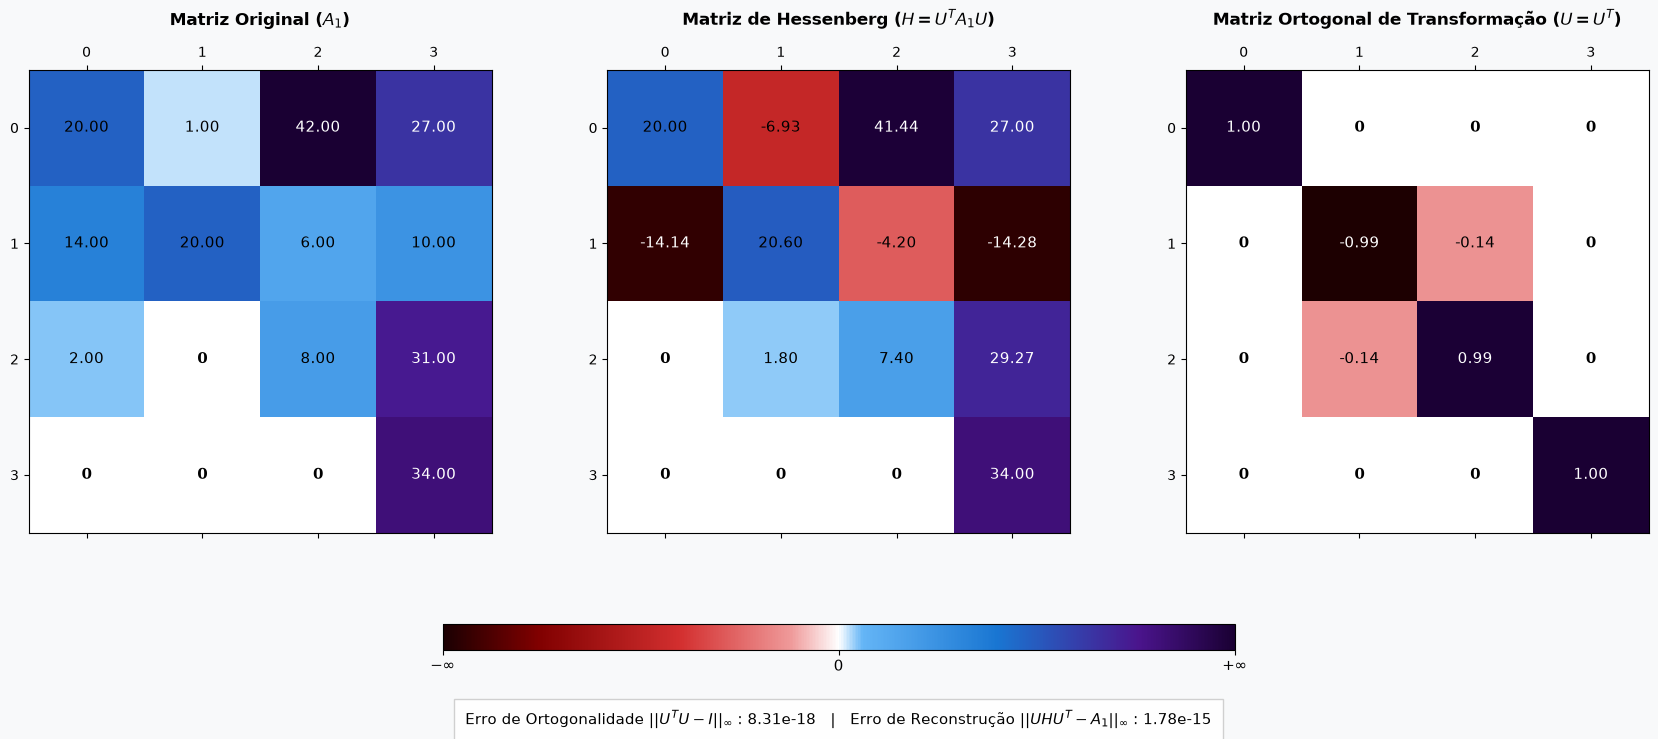

In [56]:
U, H = hessenberg_reduction(A1)
visualizar_reducao(A1, H, U)

Para zerar as entradas da primeira coluna de $A_1$ abaixo da primeira subdiagonal, aniquilando o $2.00$ na posição $a_{31}$ (posição $(2, 0)$ em Python) usando o $14.00$ na posição $a_{21}$ ($(1, 0)$ em Python) como pivô, o algoritmo extrai o subvetor ativo:

$$x = \begin{bmatrix} 14.00 \\ 2.00 \\ 0 \end{bmatrix}$$

A norma-2 deste vetor,

$$\|x\|_2 = \sqrt{14^2 + 2^2 + 0^2} = \sqrt{200} \approx 14.1421\dots$$

será concentrada na subdiagonal de $H$. Para evitar cancelamento catastrófico, o algoritmo projeta $x$ no vetor $-\|x\|_2e_1$, gerando o vetor de reflexão de Householder $v$:

$$v = x - (-\|x\|_2)e_1 = \begin{bmatrix} 14.00 \\ 2.00 \\ 0 \end{bmatrix} + \begin{bmatrix} 14.1421\dots \\ 0 \\ 0 \end{bmatrix} \approx \begin{bmatrix} 28.14 \\ 2.00 \\ 0 \end{bmatrix}$$

A matriz ortogonal local é construída via $P = I - cvv^T$, onde $c = \frac{2}{v^Tv}$. Analisando os elementos da matriz $U$, por exemplo $u_{32} = u_{23} = -0.14$, este elemento é calculado pelo produto cruzado dos componentes de $v$:

$$u_{32} = u_{23} = 0 - c \cdot v_1 \cdot v_2$$

onde $v_1 \approx 28.142$ e $v_2 = 2$ e a multiplicação garantindo a existência de um valor não-nulo fora da diagonal. Ao realizarmos a aritmética completa com o escalar $c$:

$$u_{32} \approx - \left(\frac{2}{28.142^2 + 2^2}\right) \cdot (28.142) \cdot (2) \approx -0.14142...$$

Além disso, observando a submatriz central $2 \text{ x } 2$ de $U$:

$$\begin{bmatrix} -0.99 & -0.14 \\ -0.14 & 0.99 \end{bmatrix}$$

vemos uma matriz de reflexão no $\mathbb{R}^2$, que tem a forma

$$\begin{bmatrix} -\cos(2\theta) & -\sin(2\theta) \\ -\sin(2\theta) & \cos(2\theta) \end{bmatrix}$$

Diante do exposto, podemos afirmar que a entrada $a_{31} = 2.00$ foi zerada, $h_{31} = 0$, na matriz $H$.

## STEP 2: Hessenberg's QR Iterative Step with Givens Rotations

Com a matriz $A_1$ reduzida à forma de Hessenberg superior $H = U^TA_1U$, o objetivo agora é aplicar sucessivas transformações ortogonais de similaridade sobre $H$ até que ela convirja para a matriz quase triangular superior $T$ da Decomposição Real de Schur:

$$A_1 = QTQ^T$$

extraindo em seguida os autovalores de $A_1$.

### 2.1. Custo assintótico dos métodos

#### Rotações de Givens

Vale ressaltar que um dos objetivos, em outras palavras, é aniquilar as entradas da subdiagonal da matriz $H$, no caso $h_{21} = -14.14$ e $h_{32} = 1.80$. Uma matriz de rotação de Givens $G_j$ atua no plano bidimensional através da submatriz $2 \text{ x } 2$:

$$\begin{bmatrix} G_{jj} & G_{jj+1} \\ G_{j+1j} & G_{j+1j+1} \end{bmatrix} = \begin{bmatrix} -\cos & -\sin \\ -\sin & \cos \end{bmatrix}$$

Aplicando esta matriz $G_j$ sobre $H$ temos $4$ multiplicações e $2$ adições, logo, $6$ operações de ponto flutuante (flops) por coluna, indo de $j \to n$, então:

$$\sum_{j=1}^{n-1} 6(n-j) = 6 \sum_{k=1}^{n-1} k = 6 \left(\frac{n(n-1)}{2}\right) = 3n^2 - 3n$$

Assintoticamente, a fatoração $H = QR$ custa $\mathcal{O}(n^2)$.

O algoritmo QR exige que a matriz ortogonal seja aplicada à direita para completar a transformação de similaridade:

$$H_{\text{next}} = R Q = R (G_1^T G_2^T \dots G_{n-1}^T)$$

Somando ambas as etapas, a iteração QR completa usando Givens em uma matriz de Hessenberg exige $\approx 6n^2 = \mathbf{\mathcal{O}(n^2)}$ flops.

#### Reflexão de Householder

Se aplicarmos o algoritmo QR diretamente sobre uma matriz densa usando matrizes de reflexão de Householder $P_j = I - 2vv^T$ temos outro cenário. O vetor de reflexão $v$ tem dimensão $n-j+1$. A atualização da submatriz $(n-j+1) \times (n-j+1)$ à direita e abaixo do pivô exige calcular o produto exterior $v (v^T A)$, o que consome aproximadamente $4(n-j)^2$ flops. Integrando esse custo sobre todas as colunas obtemos $\frac{4}{3}n^3$, ou seja, o limite de $\mathbf{\mathcal{O}(n^3)}$ operações de ponto flutuante.

### 2.2. Decomposição de Schur e Autovalores

Dados os elementos $h_{jj}$ da diagonal e $h_{j+1j}$ da subdiagonal de $H$, queremos determinar o $\cos$ e o $\sin$ de uma rotação de Givens que anule a segunda componente do vetor $\begin{bmatrix} h_{jj} \\ h_{j+1j} \end{bmatrix}$. A condição que define $\cos = c$ e $\sin = s$ é:

$$\begin{bmatrix} c & -s \\ s & c \end{bmatrix}^T \begin{bmatrix} h_{jj} \\ h_{j+1j} \end{bmatrix} = \begin{bmatrix} c & s \\ -s & c \end{bmatrix} \begin{bmatrix} h_{jj} \\ h_{j+1j} \end{bmatrix} = \begin{bmatrix} r \\ 0 \end{bmatrix}, \quad \text{onde } r = \sqrt{(h_{jj})^2 + (h_{j+1j})^2}$$

Efetuando a multiplicação, obtemos:

1. Primeira linha: $ch_{jj} + sh_{j+1j} = r$
2. Segunda linha: $-sh_{jj} + ch_{j+1j} = 0$

que decorre diretamente,

$$c = \frac{h_{jj}}{r}, \qquad s = \frac{h_{j+1j}}{r}, \qquad \text{com } r = \sqrt{(h_{jj})^2 + (h_{j+1j})^2}$$

Caso $r = 0$, ou seja, $h_{jj} = h_{j+1j} = 0$, tomamos simplesmente $c = 1$ e $s = 0$, que corresponde à matriz identidade.

#### 2.2.1. Monitoramento da Subdiagonal, Desacoplamento e Autovalores

A cada passo iterativo QR de Hessenberg:

1. Monitoramento e Desacoplamento: Inspecionamos as entradas da subdiagonal $h_{j+1j}$. Quando o $\|h_{j+1j}\|$ se torna suficientemente pequeno, zeramos explicitamente esta entrada, ficando $h_{j+1j} = 0$, desacoplamos o problema em subproblemas menores. Optamos por uma tolerância $tol \approx 10^{-12}$, $3$ ordens de grandeza de diferença à precisão da máquina.

2. Convergência para a Forma Real de Schur (problema 1a): Quando todas as entradas subdiagonais convergirem a zero, ou restarem apenas  blocos  $2 \times 2$ irredutíveis correspondentes a autovalores complexos conjugados, o algoritmo termina. A matriz resultante é $T$, e a matriz acumulada das transformações ortogonais ($U$ de Householder multiplicada por todas as matrizes $G_j$ de Givens) é $Q$ satisfazendo:

$$A_1 = QTQ^T$$

3. Extração dos Autovalores (problema 1b): Como $A_1$ e $T$ são similares, ou seja, $T = Q^TA_1Q$, elas possuem os mesmos autovalores, $\lambda(A_1) = \lambda(T)$.

    * Para cada bloco diagonal $1 \times 1$ de $T$, o próprio elemento diagonal $t_{ii}$ é um autovalor real de $A_1$.
    * Caso exista algum bloco diagonal $2 \times 2$ da forma $\begin{bmatrix} a & b \\ c & d \end{bmatrix}$ (com $c \neq 0$), seus autovalores são obtidos pela fórmula quadrática de autovalores-schur:

$$\lambda_{1,2} = \frac{a+d}{2} \pm \frac{\sqrt{(a-d)^2 + 4bc}}{2}$$

O passo iterativo QR de Hessenberg com rotações de Givens está implementado nas funções `givens()`, `hessenberg_qr_step()`, `schur_real_decomposition()` e `extract_eigenvalues_schur()` abaixo.

In [57]:
def givens(a: float, b: float):
  """
  Calculates cos and sin of Givens Rotation, such that:

  [[ c,  s], [-s,  c]] @ [[a], [b]] = [[r], [0]], with r = sqrt(a^2 + b^2).
  """
  r = float(np.sqrt(a * a + b * b))
  if r == 0.0:
    return 1.0, 0.0
  c = a / r
  s = b / r
  return c, s


def hessenberg_qr_step(H: np.ndarray, Q: np.ndarray):
  """
  Executes a iterative Hessenberg QR step.
  Overwrite H white Q_step^T H Q_step e updates Q <- Q Q_step.
  """
  n = H.shape[0]
  cs_list = []

  for j in range(n - 1):
    c, s = givens(H[j, j], H[j + 1, j])
    cs_list.append((c, s))

    line_j = H[j, j:n].copy()
    line_j1 = H[j + 1, j:n].copy()

    H[j, j:n] = c * line_j + s * line_j1
    H[j + 1, j:n] = -s * line_j + c * line_j1

  for j in range(n - 1):
    c, s = cs_list[j]

    col_j = H[0 : j + 2, j].copy()
    col_j1 = H[0 : j + 2, j + 1].copy()

    H[0 : j + 2, j] = c * col_j + s * col_j1
    H[0 : j + 2, j + 1] = -s * col_j + c * col_j1

    q_col_j = Q[:, j].copy()
    q_col_j1 = Q[:, j + 1].copy()

    Q[:, j] = c * q_col_j + s * q_col_j1
    Q[:, j + 1] = -s * q_col_j + c * q_col_j1

  return H, Q


def schur_real_decomposition(
    A: np.ndarray, tol: float = 1e-12, max_iter: int = 1000
):
  """
  Calculates the Schur Real Decomposition A = Q T Q^T.
  """
  # Hessenberg Reduction
  Q, T = hessenberg_reduction(A)
  n = T.shape[0]

  iterations = 0
  for k in range(1, max_iter + 1):
    iterations = k
    T, Q = hessenberg_qr_step(T, Q)

    max_subdiag = 0.0
    for j in range(n - 1):
      scale = abs(T[j, j]) + abs(T[j + 1, j + 1])
      if scale == 0.0:
        scale = 1.0
      if abs(T[j + 1, j]) <= tol * scale:
        T[j + 1, j] = 0.0
      else:
        if abs(T[j + 1, j]) > max_subdiag:
          max_subdiag = abs(T[j + 1, j])

    if max_subdiag == 0.0:
      break

  return Q, T, iterations


def extract_eigenvalues_schur(T: np.ndarray, tol: float = 1e-10):
  """
  Extract the eigenvalues from the quasi-triangular Schur matrix T.
  """
  n = T.shape[0]
  eigenvalues = []
  i = 0
  while i < n:
    if i == n - 1 or abs(T[i + 1, i]) <= tol:
      eigenvalues.append(T[i, i])
      i += 1
    else:
      a, b = T[i, i], T[i, i + 1]
      c, d = T[i + 1, i], T[i + 1, i + 1]
      trace = a + d
      discriminant = (a - d) ** 2 + 4.0 * b * c
      if discriminant >= 0.0:
        square = np.sqrt(discriminant)
        eigenvalues.append((trace + square) / 2.0)
        eigenvalues.append((trace - square) / 2.0)
      else:
        square_imag = np.sqrt(-discriminant)
        eigenvalues.append(complex(trace / 2.0, square_imag / 2.0))
        eigenvalues.append(complex(trace / 2.0, -square_imag / 2.0))
      i += 2

  return np.array(eigenvalues)

### 2.3 Problems 1a and 1b

In [58]:
Q_schur, T_schur, num_iter = schur_real_decomposition(
      A1, tol=1e-12, max_iter=1000
)

print(f"\n=== DECOMPOSIÇÃO DE SCHUR CONVERGIDA EM {num_iter} ITERAÇÕES ===")
print("\nMatriz Ortogonal Q (Problema 1a):")
print(Q_schur)

print("\nMatriz Triangular Superior T (Problema 1a):")
print(T_schur)

autovalores_A1 = extract_eigenvalues_schur(T_schur)
print("\n=== AUTOVALORES DE A1 EXTRAÍDOS DE T (Problema 1b) ===")
for idx, val in enumerate(autovalores_A1, start=1):
    print(f"lambda_{idx} = {val:.8f}")

# Verificações matemáticas baseadas nos slides (Slide 7 de autovalores-schur.pdf)
erro_ortog_Q = np.max(np.abs(Q_schur.T @ Q_schur - np.eye(A1.shape[0])))
erro_reconst_A1 = np.max(np.abs(Q_schur @ T_schur @ Q_schur.T - A1))
traco_A1 = np.trace(A1)
soma_lambdas = np.sum(autovalores_A1)

print("\n=== VERIFICAÇÕES DE RIGOR ===")
print(f"Erro de ortogonalidade ||Q^T Q - I||_max : {erro_ortog_Q:.2e}")
print(f"Erro da fatoração      ||Q T Q^T - A1||_max: {erro_reconst_A1:.2e}")
print(
    f"Traço(A1) = {traco_A1:.6f} | Soma dos autovalores ="
    f" {soma_lambdas:.6f}"
)


=== DECOMPOSIÇÃO DE SCHUR CONVERGIDA EM 68 ITERAÇÕES ===

Matriz Ortogonal Q (Problema 1a):
[[ 0.414938  0.901657 -0.121827  0.      ]
 [ 0.908765 -0.417248  0.007119  0.      ]
 [ 0.044413  0.113666  0.992526  0.      ]
 [ 0.        0.        0.        1.      ]]

Matriz Triangular Superior T (Problema 1a):
[[26.685569 13.918567 20.622186 21.667775]
 [ 0.       18.42664  34.438335 23.695891]
 [ 0.        0.        2.887791 27.550178]
 [ 0.        0.        0.       34.      ]]

=== AUTOVALORES DE A1 EXTRAÍDOS DE T (Problema 1b) ===
lambda_1 = 26.68556904
lambda_2 = 18.42664022
lambda_3 = 2.88779074
lambda_4 = 34.00000000

=== VERIFICAÇÕES DE RIGOR ===
Erro de ortogonalidade ||Q^T Q - I||_max : 1.89e-15
Erro da fatoração      ||Q T Q^T - A1||_max: 3.19e-11
Traço(A1) = 82.000000 | Soma dos autovalores = 82.000000


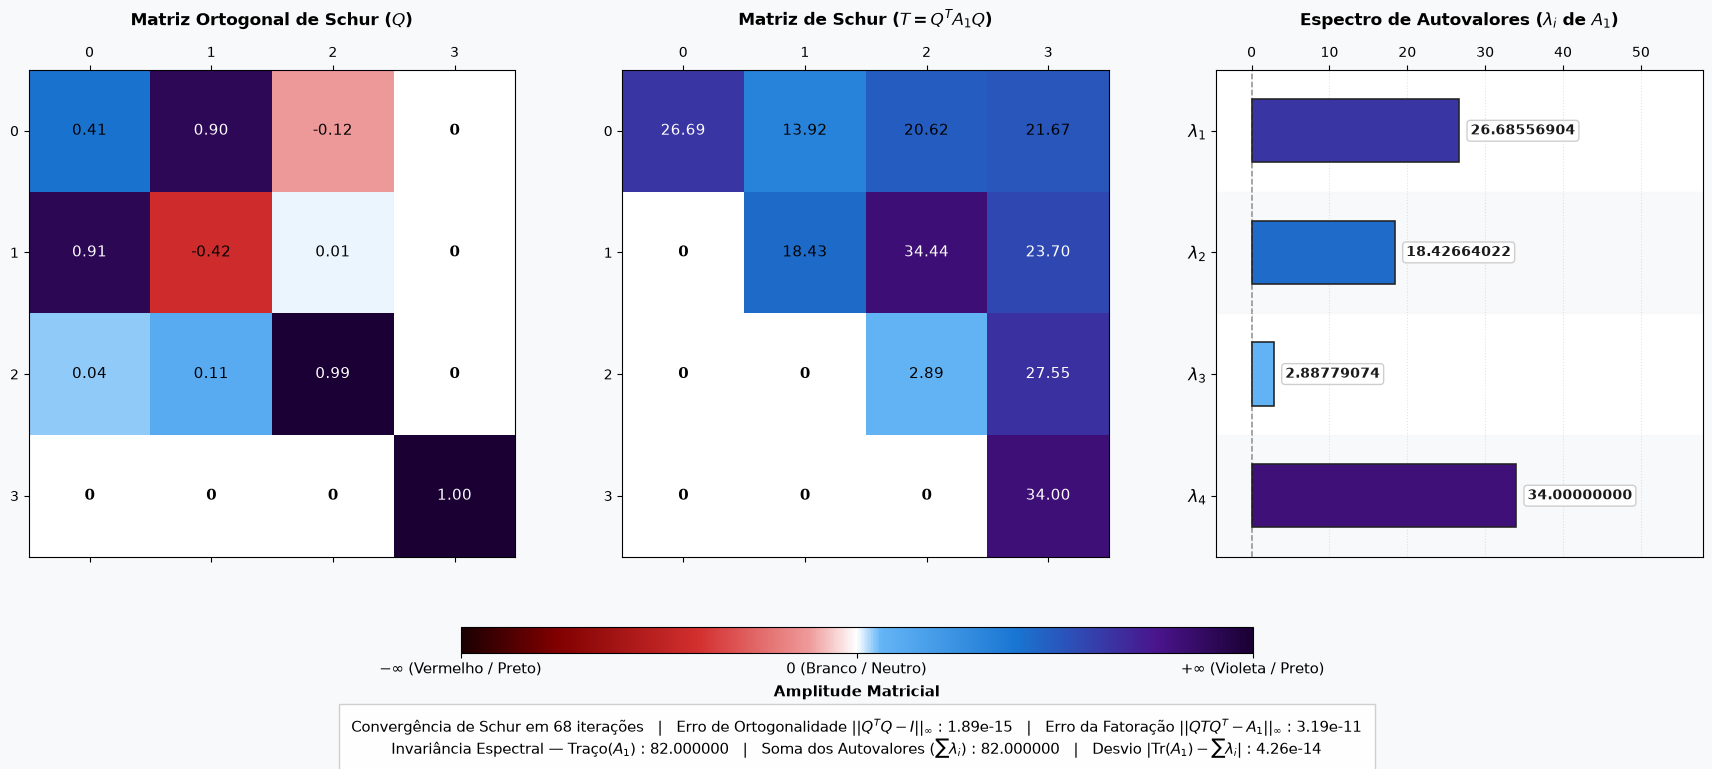

In [59]:
def renderizar_autovalores(
    ax,
    autovalores: np.ndarray,
    vmin: float,
    vmax: float,
    titulo: str = "Espectro de Autovalores ($\\lambda_i$ de $A_1$)",
):
    """Renderiza o espectro de autovalores alinhado às linhas da matriz de Schur T."""
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
    n = len(autovalores)
    y_pos = np.arange(n)
    re_vals = np.real(autovalores)
    im_vals = np.imag(autovalores)

    cores_barras = [cmap_fisica(norm(val)) for val in re_vals]

    ax.set_facecolor("#ffffff")
    ax.set_box_aspect(1)
    ax.axvline(0, color="#888888", linestyle="--", linewidth=1.1, zorder=1)
    ax.grid(axis="x", linestyle=":", alpha=0.55, color="#cccccc", zorder=0)

    # Faixas horizontais sutis alinhadas linha a linha com a diagonal de T
    for i in range(n):
        if i % 2 == 1:
            ax.axhspan(i - 0.5, i + 0.5, color="#f4f6f9", alpha=0.6, zorder=0)

    ax.barh(
        y_pos,
        re_vals,
        height=0.52,
        color=cores_barras,
        edgecolor="#222222",
        linewidth=1.15,
        zorder=3,
    )

    min_re = float(np.min(re_vals))
    max_re = float(np.max(re_vals))
    span = max(vmax - vmin, max_re - min_re, 1.0)
    x_left = min(0.0, min_re) - (0.38 * span if min_re < 0 else 0.08 * span)
    x_right = max(0.0, max_re) + (0.42 * span if max_re >= 0 else 0.12 * span)
    ax.set_xlim(x_left, x_right)
    ax.set_ylim(-0.5, n - 0.5)
    ax.invert_yaxis()

    ax.set_yticks(y_pos)
    ax.set_yticklabels(
        [f"$\\lambda_{{{i+1}}}$" for i in range(n)],
        fontsize=12,
        fontweight="bold",
    )
    ax.xaxis.tick_top()
    ax.set_title(titulo, pad=15, fontsize=12, fontweight="bold")

    for i, (re_v, im_v) in enumerate(zip(re_vals, im_vals)):
        if abs(im_v) > 1e-10:
            sinal = "+" if im_v >= 0 else "-"
            txt = f"{re_v:.4f} {sinal} {abs(im_v):.4f}i"
        else:
            txt = f"{re_v:.8f}"

        offset = 0.025 * span if re_v >= 0 else -0.025 * span
        ha_align = "left" if re_v >= 0 else "right"
        ax.text(
            re_v + offset,
            i,
            txt,
            va="center",
            ha=ha_align,
            fontsize=10,
            fontweight="bold",
            color="#1a1a1a",
            bbox={
                "facecolor": "#ffffff",
                "edgecolor": "#cccccc",
                "boxstyle": "round,pad=0.25",
                "alpha": 0.95,
            },
            zorder=4,
        )


def visualizar_schur(
    A: np.ndarray,
    Q: np.ndarray,
    T: np.ndarray,
    autovalores: np.ndarray,
    num_iter: int,
):
    """Visualiza de forma responsiva as matrizes Q e T de Schur, os autovalores e as métricas de rigor."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 7.8))
    fig.patch.set_facecolor("#f8f9fa")

    # Limites dinâmicos responsivos às entradas de A e T (mantendo a referência física [-15, 42])
    vmin_dinamico = min(-15.0, float(np.min(A)), float(np.min(T)))
    vmax_dinamico = max(42.0, float(np.max(A)), float(np.max(T)))

    # 1. Matriz Ortogonal de Schur (Q) - Problema 1a
    renderizar_matriz(
        axes[0], Q, "Matriz Ortogonal de Schur ($Q$)", vmin=-1.0, vmax=1.0
    )

    # 2. Matriz Triangular Superior de Schur (T) - Problema 1a
    cax_T = renderizar_matriz(
        axes[1],
        T,
        "Matriz de Schur ($T = Q^T A_1 Q$)",
        vmin=vmin_dinamico,
        vmax=vmax_dinamico,
    )

    # 3. Espectro de Autovalores extraídos de T - Problema 1b
    renderizar_autovalores(
        axes[2], autovalores, vmin=vmin_dinamico, vmax=vmax_dinamico
    )

    # Barra de cores horizontal como legenda da escala física
    cbar_ax = fig.add_axes([0.28, 0.145, 0.44, 0.033])
    cbar = fig.colorbar(cax_T, cax=cbar_ax, orientation="horizontal")
    cbar.set_ticks([vmin_dinamico, 0, vmax_dinamico])
    cbar.set_ticklabels([
        r"$-\infty$ (Vermelho / Preto)",
        r"$0$ (Branco / Neutro)",
        r"$+\infty$ (Violeta / Preto)",
    ])
    cbar.ax.tick_params(labelsize=10.5)
    cbar.set_label(
        "Amplitude Matricial",
        fontsize=11,
        fontweight="bold",
        labelpad=5,
    )

    # Cálculo dinâmico das verificações de rigor matemático
    erro_ortog_Q = np.max(np.abs(Q.T @ Q - np.eye(A.shape[0])))
    erro_reconst_A = np.max(np.abs(Q @ T @ Q.T - A))
    traco_A = float(np.trace(A))
    soma_lambdas = float(np.real(np.sum(autovalores)))
    erro_traco = abs(traco_A - soma_lambdas)

    texto_metricas = (
        f"Convergência de Schur em {num_iter} iterações   |   "
        f"Erro de Ortogonalidade $||Q^T Q - I||_{{\\infty}}$ : {erro_ortog_Q:.2e}   |   "
        f"Erro da Fatoração $||Q T Q^T - A_1||_{{\\infty}}$ : {erro_reconst_A:.2e}\n"
        f"Invariância Espectral — $\\mathrm{{Traço}}(A_1)$ : {traco_A:.6f}   |   "
        f"Soma dos Autovalores ($\\sum \\lambda_i$) : {soma_lambdas:.6f}   |   "
        f"Desvio $|\\mathrm{{Tr}}(A_1) - \\sum \\lambda_i|$ : {erro_traco:.2e}"
    )

    plt.figtext(
        0.5,
        0.015,
        texto_metricas,
        ha="center",
        fontsize=10.5,
        linespacing=1.45,
        bbox={
            "facecolor": "white",
            "alpha": 0.92,
            "pad": 9,
            "edgecolor": "#cccccc",
        },
    )

    plt.subplots_adjust(top=0.90, bottom=0.26, left=0.04, right=0.97, wspace=0.22)
    plt.show()


# Execução responsiva (Problemas 1a e 1b)
Q_schur, T_schur, num_iter = schur_real_decomposition(
    A1, tol=1e-12, max_iter=1000
)
autovalores_A1 = extract_eigenvalues_schur(T_schur)

visualizar_schur(A1, Q_schur, T_schur, autovalores_A1, num_iter)

### 2.4 Problema 1c - Avaliação dos Resultados

In [60]:
# 1. Extração da submatriz 3x3 superior esquerda de A1 e seu determinante
submatriz_3x3 = A1[:3, :3]
det_sub_3x3 = float(np.linalg.det(submatriz_3x3))

# 2. Multiplicação pelo elemento desacoplado a_44 (34.0)
a_44 = float(A1[3, 3])
det_A1_bloco = a_44 * det_sub_3x3

# 3. Produto dos autovalores extraídos de T (em precisão dupla completa)
prod_autovalores = float(np.real(np.prod(autovalores_A1)))

# 4. Medição do erro absoluto e relativo
erro_absoluto = abs(det_A1_bloco - prod_autovalores)
erro_relativo = erro_absoluto / abs(det_A1_bloco)

print(f"Determinante da submatriz 3x3 de A1          : {det_sub_3x3:.8f}")
print(f"{a_44:.0f} x det(submatriz 3x3 de A1)                : {det_A1_bloco:.8f}")
print(f"Produto dos autovalores (prod lambda_i)      : {prod_autovalores:.8f}")
print(f"Erro absoluto |34*det(A_3x3) - prod lambda_i|: {erro_absoluto:.2e}")
print(f"Erro relativo                                : {erro_relativo:.2e}")

Determinante da submatriz 3x3 de A1          : 1420.00000000
34 x det(submatriz 3x3 de A1)                : 48280.00000000
Produto dos autovalores (prod lambda_i)      : 48280.00000017
Erro absoluto |34*det(A_3x3) - prod lambda_i|: 1.73e-07
Erro relativo                                : 3.59e-12


In [61]:
# ETAPA 3: SENSIBILIDADE DO PROBLEMA DE AUTOVALOR (Problema 1c)
def autovetores_via_schur(Q: np.ndarray, T: np.ndarray):
  """Calcula manualmente os autovetores à direita (x_i) e à esquerda (y_i) de A = Q T Q^T

  usando substituição regressiva em T e substituição progressiva em T^T.
  Normaliza x_i e y_i exatamente como no Exemplo 2 (Slide 12 -
  pertubacao-potencia.pdf): ||x_i||_2 = 1 e y_i^T x_i = 1.
  """
  n = T.shape[0]
  X_dir = np.zeros((n, n), dtype=float)
  Y_esq = np.zeros((n, n), dtype=float)
  cond_autovalores = np.zeros(n, dtype=float)
  angulos_graus = np.zeros(n, dtype=float)

  for i in range(n):
    lam = T[i, i]

    # 1. Autovetor à direita de T: (T - lam*I) v = 0 por substituição regressiva
    v = np.zeros(n, dtype=float)
    v[i] = 1.0
    for k in range(i - 1, -1, -1):
      soma = 0.0
      for m in range(k + 1, i + 1):
        soma += T[k, m] * v[m]
      v[k] = -soma / (T[k, k] - lam)

    # 2. Autovetor à esquerda de T: (T^T - lam*I) w = 0 por substituição progressiva
    w = np.zeros(n, dtype=float)
    w[i] = 1.0
    for k in range(i + 1, n):
      soma = 0.0
      for m in range(i, k):
        soma += T[m, k] * w[m]
      w[k] = -soma / (T[k, k] - lam)

    # 3. Projeta para a base original de A: x = Q v, y = Q w
    x = Q @ v
    y = Q @ w

    # 4. Normalização do Slide 12: ||x||_2 = 1 e y^T x = 1
    norma_x = calc_norm_2(x)
    x = x / norma_x
    prod_interno = float(y.T @ x)
    y = y / prod_interno  # Agora y^T x = 1 exatamente

    # 5. Número de condição: 1 / |cos(theta)| = ||x||_2 * ||y||_2
    norma_y = calc_norm_2(y)
    cond_i = (
        1.0 * norma_y
    )  # Pois ||x||_2 = 1 e |y^T x| = 1 -> cos(theta) = 1 / ||y||_2
    cos_theta = 1.0 / cond_i
    theta_deg = float(np.degrees(np.arccos(np.clip(cos_theta, -1.0, 1.0))))

    X_dir[:, i] = x
    Y_esq[:, i] = y
    cond_autovalores[i] = cond_i
    angulos_graus[i] = theta_deg

  return X_dir, Y_esq, cond_autovalores, angulos_graus


def analisar_sensibilidade_A1(A: np.ndarray, Q: np.ndarray, T: np.ndarray):
  """Exibe o relatório completo de sensibilidade para responder ao Problema 1c."""
  n = A.shape[0]
  lambdas = np.diag(T)
  X_dir, Y_esq, conds, angulos = autovetores_via_schur(Q, T)

  # Verificação de não-normalidade: ||A^T A - A A^T||_max
  desvio_normalidade = np.max(np.abs(A.T @ A - A @ A.T))

  print("\n" + "=" * 75)
  print("ETAPA 3: ANÁLISE DE SENSIBILIDADE DO PROBLEMA DE AUTOVALOR (ITEM 1c)")
  print("=" * 75)
  print(f"Desvio de normalidade ||A1^T A1 - A1 A1^T||_max: {desvio_normalidade:.2f} (Matriz Não-Normal)")
  print("-" * 75)
  print(
      f"{'Autovalor':<10} | {'Valor (lambda_i)':<14} | {'cond = 1/|cos(θ)|':<17}"
      f" | {'Ângulo θ (x_i, y_i)':<19} | {'Dist. mín |λ_i - λ_j|'}"
  )
  print("-" * 75)

  for i in range(n):
    # Menor distância até outro autovalor
    dist_min = min(abs(lambdas[i] - lambdas[j]) for j in range(n) if j != i)
    print(
        f"lambda_{i+1:<3} | {lambdas[i]:<14.8f} | {conds[i]:<17.6f} |"
        f" {angulos[i]:<18.4f}° | {dist_min:.6f}"
    )

    # Verifica resíduos dos autovetores calculados manualmente
    res_dir = calc_norm_2(A @ X_dir[:, i] - lambdas[i] * X_dir[:, i])
    res_esq = calc_norm_2(A.T @ Y_esq[:, i] - lambdas[i] * Y_esq[:, i])
    if max(res_dir, res_esq) > 1e-9:
      print(
          f"  [Aviso] Resíduo autovetor {i+1}: dir={res_dir:.2e},"
          f" esq={res_esq:.2e}"
      )

  print("-" * 75)

In [62]:
analisar_sensibilidade_A1(A1, Q_schur, T_schur)


ETAPA 3: ANÁLISE DE SENSIBILIDADE DO PROBLEMA DE AUTOVALOR (ITEM 1c)
Desvio de normalidade ||A1^T A1 - A1 A1^T||_max: 2294.00 (Matriz Não-Normal)
---------------------------------------------------------------------------
Autovalor  | Valor (lambda_i) | cond = 1/|cos(θ)| | Ângulo θ (x_i, y_i) | Dist. mín |λ_i - λ_j|
---------------------------------------------------------------------------
lambda_1   | 26.68556904    | 21.222548         | 87.2992           ° | 7.314431
lambda_2   | 18.42664022    | 11.680828         | 85.0889           ° | 8.258929
lambda_3   | 2.88779074     | 3.298015          | 72.3493           ° | 15.538849
lambda_4   | 34.00000000    | 12.642448         | 85.4632           ° | 7.314431
---------------------------------------------------------------------------


Para responder sobre a questão da sensibilidade do problema de autovalor precisamos analisar alguns aspectos dos resultados, entre eles:

1. Podemos constatar que a soma dos elementos da diagonal principal de $A_1$ é $\text{tr}(A_1) = 20 + 20 + 8 + 34 = 82$, que coincide com a soma dos autovalores $\sum\limits_{i=1}^4 \lambda_i = 82.000000$. Esse resultado confirma que nossa matriz de Schur de $T$ foi construída corretamente. Além disso, como a 4ª linha de $A_1$ é $\begin{bmatrix} 0 & 0 & 0 & 34 \end{bmatrix}$, temos que o determinante de $A_1$ é 34 vezes o determinante do  bloco  superior esquerdo $3 \times 3$:

$$\det A_1 = 34 \cdot \begin{bmatrix} 20.00 & 1.00 & 42.00 \\ 14.00 & 20.00 & 6.00 \\ 2.00 & 0.00 & 8.00 \end{bmatrix} = 48280.00000000$$

Por outro lado, multiplicando os elementos da diagonal principal da matriz de Schur $T$, nós obtemos:

$$\lambda_1 \cdot \lambda_2 \cdot \lambda_3 \cdot \lambda_4 = 26.68556904 \cdot 18.42664022 \cdot 2.88779074 \cdot 34.00000000 = 48280.00000017$$

2. Os quatro autovalores de $A_1$ são todos distintos, cada autovalor possui multiplicidade algébrica e geométrica igual a 1, sendo autovalores simples, então $A_1$ é diagonalizável, não-defeituosa, e não sofre hipersensibilidade por blocos de Jordan (pequenos erros de arredondamento afetam os autovalores).

3. Os números de condição $\text{cond}(\lambda_i) = 1/\vert{}\cos\theta_i\vert{}$ situam-se entre $3.30$ (para $\lambda_3$) e $21.22$ (para $\lambda_1$). Isso significa que uma perturbação de ordem $\epsilon$ nos dados de $A_1$ é amplificada em no máximo $\approx 21.2$ vezes (perda de no máximo $\approx 1$ dígito decimal significativo).

4. Como $A_1$ não é uma matriz normal ($A_1^T A_1 \neq A_1 A_1^T$), os autovetores à direita e à esquerda não são colineares: para $\lambda_1$, o ângulo entre $x_1$ e $y_1$ chega a $87.30^\circ$ (quase ortogonais, porém ainda longe de degenerar), fazendo de $\lambda_1$ o autovalor relativamente mais sensível dos quatro, enquanto $\lambda_3$ ($\theta_3 \approx 72.35^\circ$, $\text{cond}(\lambda_3) \approx 3.30$) é o menos sensível.

5. Como os autovalores estão bem espaçados entre si (a menor distância é $\vert{}\lambda_4 - \lambda_1\vert{} \approx 7.31$, e $\lambda_3$ está isolado a uma distância de $15.54$ de $\lambda_2$), não há agrupamento espectral, garantindo que os vetores de Schur e autovetores associados também sejam pouco sensíveis a perturbações.

## STEP 3:

In [63]:
print(A2)

[[ -8.  -1.   0.   2.   1.]
 [ -7.  -2.   9.   7.   2.]
 [  4.   3.  16.  -2.  -2.]
 [ -7.   3.   4.  -9.  -2.]
 [  0.  -2.  -7.  -7. -16.]]


Dada a matriz $5 \times 5$,

$$A_2 = \begin{bmatrix} -8 & -1 & 0 & 2 & 1 \\ -7 & -2 & 9 & 7 & 2 \\ 4 & 3 & 16 & -2 & -2 \\ -7 & 3 & 4 & -9 & -2 \\ 0 & -2 & -7 & -7 & -16 \end{bmatrix}$$

inicialmente queremos determinar o autovalor dominante da matriz $A_2$ utilizando o método da potência, escolhendo adequadamente o vetor inicial $x^{(0)}$, adotando o erro relativo entre aproximações sucessivas como critério de parada (problema 2a) e apresentando a tabela iterativa completa (problema 2b).

### 3.1 Dedução e Condição de Convergência

Assumindo que $A \in \mathbb{R}^{n \times n}$ é diagonalizável, assim possuindo $n$ autovetores linearmente independentes $x_1, \dots, x_n$, e que seus autovalores estão ordenados em módulo com um autovalor estritamente dominante:

$$\vert{}\lambda_1\vert{} > \vert{}\lambda_2\vert{} \ge \dots \ge \vert{}\lambda_n\vert{}$$

Qualquer vetor inicial não nulo $x^{(0)} \in \mathbb{R}^{n}$ pode ser escrito como combinação linear da base de autovetores:

$$x^{(0)} = c_1x_1 + \dots + c_nx_n$$

Multiplicando repetidamente por $A$ ($x^{(k)} = A x^{(k-1)} = A^k x^{(0)}$) e colocando $\lambda_1^k$ em evidência, obtemos:

$$x^{(k)} = \sum_{i=1}^n c_i \lambda_i^k x_i = \lambda_1^k \left[ c_1 x_1 + \sum_{i=2}^n c_i \left(\frac{\lambda_i}{\lambda_1}\right)^k x_i \right]$$

Desde que $c_1 \neq 0$ (ou seja, $x^{(0)}$ tenha componente não nula na direção de $x_1$) e $\vert{}\lambda_1\vert{} > \vert{}\lambda_i\vert{}$ para todo $i \ge 2$, os termos $\left(\frac{\lambda_i}{\lambda_1}\right)^k \to 0$ quando $k \to \infty$. Assim, a direção de $x^{(k)}$ converge para a direção do autovetor dominante $x_1$.

### 3.2 Algoritmo, Normalização de Sinal e Quociente de Rayleigh

Para evitar overflow ou underflow numérico causado pela potência $\lambda_1^k$, normalizamos o vetor a cada iteração:

1. Tomamos $x^{(0)} \neq 0$ e definimos $q_0 = \frac{x^{(0)}}{\Vert{}x^{(0)}\Vert{}_2}$ de modo que $\Vert{}q_0\Vert{}_2 = 1$.

2. Passo iterativo ($k = 1, 2, \dots$):
    * Calculamos o produto matriz-vetor: $z_k = A q_{k-1}$.
    * Normalizamos na norma-2: $q_k = \frac{z_k}{\Vert{}z_k\Vert{}_2}$.
    * Se $\lambda_1 < 0$, o vetor $q_k$ alterna de sentido a cada iteração ($+q_k$ e $-q_k$). Contornamos o cenário impondo que a primeira componente não nula de $q_k$ seja sempre positiva.

3. Aproximação do Autovalor via Quociente de Rayleigh: A cada iteração $k$, obtemos a aproximação do autovalor dominante $\lambda^{(k)}$ aplicando o Quociente de Rayleigh ao vetor unitário $q_k$:

$$\lambda^{(k)} = r(q_k, A) \equiv \frac{q_k^T A q_k}{q_k^T q_k} = q_k^T A q_k \quad (\text{pois } q_k^T q_k = \Vert{}q_k\Vert{}_2^2 = 1)$$

4. Critério de Parada por Erro Relativo (Problema 2a): Para $k \ge 1$, monitoramos o erro relativo entre duas aproximações sucessivas de $\lambda_1$:

$$\text{Erro Relativo}^{(k)} = \frac{\left\vert{}\lambda^{(k)} - \lambda^{(k-1)}\right\vert{}}{\left\vert{}\lambda^{(k)}\right\vert{}} < \text{tol}$$

A condição de convergência, com a normalização de sinal e quociente de Rayleigh está implementada nas funções em linguagem Python a seguir.

In [64]:
def produto_interno_manual(u: np.ndarray, v: np.ndarray) -> float:
  """Calcula o produto interno u^T v manualmente."""
  soma = 0.0
  u_flat = u.flatten()
  v_flat = v.flatten()
  for i in range(len(u_flat)):
    soma += u_flat[i] * v_flat[i]
  return float(soma)


def quociente_rayleigh(q: np.ndarray, A: np.ndarray) -> float:
  """Calcula o Quociente de Rayleigh r(q, A) = (q^T A q) / (q^T q)."""
  Aq = A @ q
  numerador = produto_interno_manual(q, Aq)
  denominador = produto_interno_manual(q, q)
  return numerador / denominador


def normalizar_com_sinal(z: np.ndarray) -> np.ndarray:
  """
    Normaliza o vetor na norma-2 e garante que a primeira
    componente não nula seja positiva.
  """
  norma = calc_norm_2(z)
  if norma == 0.0:
    raise ValueError("O vetor nulo foi atingido durante a iteracao.")
  q = z / norma

  # Ajuste de sinal do Slide 26: primeira componente não nula positiva
  for comp in q.flatten():
    if abs(comp) > 1e-14:
      if comp < 0.0:
        q = -q
      break
  return q


def metodo_da_potencia(
    A: np.ndarray, x0: np.ndarray, tol: float = 1e-8, max_iter: int = 2000
):
  """Algoritmo do Método da Potência.

  Retorna:
    - lambda_dom: autovalor dominante aproximado
    - q_k: autovetor unitário correspondente
    - historico: lista de tuplas (iteracao, lambda_k, erro_relativo) para a
    tabela do item 2b.
  """
  # Linha 1: Escolha q_0 de modo que ||q_0||_2 = 1
  q_k = normalizar_com_sinal(x0.astype(float).copy())

  # Aproximação inicial (k = 0) via Quociente de Rayleigh
  lambda_ant = quociente_rayleigh(q_k, A)
  historico = []

  # Linha 2: para k = 1, 2, ... até a convergência faça
  for k in range(1, max_iter + 1):
    # Linha 3: z_k = A q_{k-1}
    z_k = A @ q_k

    # Linha 4: q_k = z_k / ||z_k||_2 (com ajuste de sinal)
    q_k = normalizar_com_sinal(z_k)

    # Cálculo da aproximação do autovalor dominante via Quociente de Rayleigh
    lambda_atual = quociente_rayleigh(q_k, A)

    # Erro relativo entre aproximações sucessivas (Problema 2a)
    if abs(lambda_atual) > 0.0:
      erro_rel = abs(lambda_atual - lambda_ant) / abs(lambda_atual)
    else:
      erro_rel = abs(lambda_atual - lambda_ant)

    historico.append((k, lambda_atual, erro_rel))

    # Critério de parada
    if erro_rel < tol:
      break

    lambda_ant = lambda_atual

  return lambda_atual, q_k, historico

In [65]:
# Problema 2b
def imprimir_tabela_potencia(historico: list, passo_amostragem: int = 1):
  """
    Imprime a tabela exigida no Problema 2b:
    Número da iteração (k), Aproximação do autovalor dominante e Erro relativo.
  """
  print("\n" + "=" * 62)
  print(f"{'Iteração (k)':^14} | {'Autovalor Dominante (λ_k)':^25} | {'Erro Relativo':^17}")
  print("=" * 62)

  total = len(historico)
  for idx, (k, lam_k, erro_k) in enumerate(historico):
    # Exibe as primeiras 10, as múltiplos de passo_amostragem e as últimas 5 iterações
    # (Se passo_amostragem == 1, exibe absolutamente todas as linhas)
    if (
        passo_amostragem == 1
        or k <= 10
        or k % passo_amostragem == 0
        or idx >= total - 5
    ):
      print(f"{k:^14d} | {lam_k:^25.10f} | {erro_k:^17.6e}")
  print("=" * 62)

In [66]:
print("\n" + "#" * 75)
print("PROBLEMA 2: MÉTODO DA POTÊNCIA NA MATRIZ A2")
print("#" * 75)
print("Matriz A2:")
print(A2)

# Escolha adequada do vetor inicial x^(0) alinhado ao disco de Gershgorin de a_33 = 16
x0_adequado = np.array([0.0, 0.0, 1.0, 0.0, 0.0], dtype=float)
tolerancia = 1e-8

lambda_dom, autovetor_dom, hist = metodo_da_potencia(
    A2, x0=x0_adequado, tol=tolerancia, max_iter=2000
)

# Use passo_amostragem=1 para ver todas as linhas ou passo_amostragem=20 para resumir no terminal
imprimir_tabela_potencia(hist, passo_amostragem=20)

residuo_par = calc_norm_2(
    A2 @ autovetor_dom - lambda_dom * autovetor_dom
)
    
print(f"\nResultado Final Convergido (tol = {tolerancia:.0e}):")
print(f"  Iterações até convergência : {len(hist)}")
print(f"  Autovalor dominante (λ_1)  : {lambda_dom:.10f}")
print(
    f"  Autovetor unitário (q_k)   : {np.round(autovetor_dom, 6)}"
)
print(f"  Resíduo ||A2*q - λ_1*q||_2 : {residuo_par:.2e}")


###########################################################################
PROBLEMA 2: MÉTODO DA POTÊNCIA NA MATRIZ A2
###########################################################################
Matriz A2:
[[ -8.  -1.   0.   2.   1.]
 [ -7.  -2.   9.   7.   2.]
 [  4.   3.  16.  -2.  -2.]
 [ -7.   3.   4.  -9.  -2.]
 [  0.  -2.  -7.  -7. -16.]]

 Iteração (k)  | Autovalor Dominante (λ_k) |   Erro Relativo  
      1        |       16.1243781095       |   7.713669e-03   
      2        |       18.1077301884       |   1.095307e-01   
      3        |       16.4090371438       |   1.035218e-01   
      4        |       18.1057255953       |   9.371005e-02   
      5        |       16.4449141090       |   1.009924e-01   
      6        |       18.1095471124       |   9.192019e-02   
      7        |       16.4824258535       |   9.871855e-02   
      8        |       18.1085359421       |   8.979799e-02   
      9        |       16.5284333257       |   9.559906e-02   
      10       |    